# Assignment 1: MicroGrad
**Ahmed Hossam Abdallah - 23P0109**  
CSE485-CSE488: Deep Learning

This demo checks the scalar derivatives, then trains a single neuron and a small
MLP on noisy XOR data. The CSV is included, and all random seeds are fixed.
Only the standard library is used by the engine and training loop. Matplotlib
and NumPy are used for plots, not for differentiation or optimization.

Run all cells from top to bottom. Install the demo dependencies with
`python -m pip install -r requirements.txt`, then open this notebook in Jupyter.

In [1]:
import csv
import json
import math
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'engine.py').exists(), 'Open the notebook in the project folder.'
sys.path.insert(0, str(ROOT))
from src.engine import Value
from src.nn import Neuron, MLP

random.seed(7)
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

## 1. Check the computational graph

For a shared input, $c=a+a$ and $d=ca=2a^2$. At $a=3$, the derivative should
be $4a=12$. Both paths must add to the same gradient. The DFS order must place
each parent after its inputs; backpropagation uses the reverse of that order.

In [2]:
a = Value(3.0, label='a')
c = a + a
d = c * a
topo = d._get_topo()
assert len(topo) == len(set(topo))
assert all(topo.index(child) < topo.index(node)
           for node in topo for child in node._prev)
d.backward()
assert a.grad == 12.0
print(f'd = {d.data:.1f}, dd/da = {a.grad:.1f}; expected 18.0 and 12.0')

d = 18.0, dd/da = 12.0; expected 18.0 and 12.0


The next check compares backpropagation with central finite differences for
**every parameter** of an MLP. Each parameter is restored after perturbation.
This is a numerical check, so a small tolerance is needed.

In [3]:
random.seed(11)
check_model = MLP(2, [4, 1])
check_x = [0.3, -0.8]
check_model.zero_grad()
check_model(check_x).backward()
h = 1e-6
gradient_errors = []
for p in check_model.parameters():
    original = p.data
    p.data = original + h
    plus = check_model(check_x).data
    p.data = original - h
    minus = check_model(check_x).data
    p.data = original
    numerical = (plus - minus) / (2 * h)
    gradient_errors.append(abs(p.grad - numerical))
max_gradient_error = max(gradient_errors)
assert max_gradient_error < 1e-6
print(f'Checked {len(gradient_errors)} parameters')
print(f'Maximum absolute gradient error: {max_gradient_error:.3e}')

Checked 17 parameters
Maximum absolute gradient error: 2.459e-11


## 2. Load the data

`data/xor.csv` contains 48 training samples and 24 held-out test samples.
The four clusters are centered at $(-1,-1),(-1,1),(1,-1),(1,1)$, with independent
Gaussian noise of standard deviation 0.2. Targets are -1 for equal center signs
and +1 for opposite signs, matching the tanh output range. The CSV was generated
with `random.Random(23)`; the training and test rows were sampled independently.
The split is fixed, and the test data is used only for evaluation.

XOR is useful here because one affine decision boundary cannot separate it.
This gives a reason to compare one neuron with a network that has a hidden layer.

In [4]:
with (ROOT / 'data' / 'xor.csv').open(newline='') as f:
    rows = list(csv.DictReader(f))

def load_split(split):
    selected = [row for row in rows if row['split'] == split]
    xs = [[float(row['x1']), float(row['x2'])] for row in selected]
    ys = [float(row['target']) for row in selected]
    return xs, ys

train_x, train_y = load_split('train')
test_x, test_y = load_split('test')
assert len(train_x) == 48 and len(test_x) == 24
assert train_y.count(1.0) == train_y.count(-1.0) == 24
assert test_y.count(1.0) == test_y.count(-1.0) == 12
print(f'Training: {len(train_x)}, test: {len(test_x)}')
print('First training row:', train_x[0], 'target:', train_y[0])

Training: 48, test: 24
First training row: [-0.566003, -1.221596] target: -1.0


## 3. Train the models

Both models use mean squared error,
$L=\frac{1}{N}\sum_i(\hat y_i-y_i)^2$, and full-batch gradient descent.
The parameters are updated by $p\leftarrow p-\eta\,\partial L/\partial p$.
Before each backward pass, parameter gradients are cleared. A new forward graph
is built for each update, so old intermediate gradients are not reused.

The single neuron has 3 parameters. The $2\to4\to1$ MLP has
$(2+1)4+(4+1)1=17$ parameters. Both use tanh, 600 updates, learning rate 0.1,
and initialization seed 7. These settings are fixed in advance rather than
selected using the test results.

In [5]:
EPOCHS = 600
LEARNING_RATE = 0.1

def mse(model, xs, ys):
    return sum((model(x) - y) ** 2 for x, y in zip(xs, ys)) / len(xs)

def evaluate(model, xs, ys):
    predictions = [model(x).data for x in xs]
    loss = sum((p - y) ** 2 for p, y in zip(predictions, ys)) / len(ys)
    correct = sum((1.0 if p >= 0 else -1.0) == y
                  for p, y in zip(predictions, ys))
    return {'mse': loss, 'accuracy': correct / len(ys)}

def train(model):
    history = []
    for _ in range(EPOCHS):
        loss = mse(model, train_x, train_y)
        history.append(loss.data)
        model.zero_grad()
        loss.backward()
        for p in model.parameters():
            p.data -= LEARNING_RATE * p.grad
    history.append(evaluate(model, train_x, train_y)['mse'])
    return history

random.seed(7)
baseline = Neuron(2)
baseline_history = train(baseline)
random.seed(7)
model = MLP(2, [4, 1])
mlp_history = train(model)

summary = {}
for name, net, history in [('Single neuron', baseline, baseline_history),
                           ('MLP (2-4-1)', model, mlp_history)]:
    summary[name] = {'parameters': len(net.parameters()), 'initial_mse': history[0],
                     'train': evaluate(net, train_x, train_y),
                     'test': evaluate(net, test_x, test_y)}
    print(name)
    print(json.dumps(summary[name], indent=2))

assert mlp_history[-1] < 0.1 * mlp_history[0]
assert summary['MLP (2-4-1)']['test']['accuracy'] >= 0.9

Single neuron
{
  "parameters": 3,
  "initial_mse": 1.2307724110785707,
  "train": {
    "mse": 1.0137358791721682,
    "accuracy": 0.75
  },
  "test": {
    "mse": 1.013164776050021,
    "accuracy": 0.75
  }
}
MLP (2-4-1)
{
  "parameters": 17,
  "initial_mse": 1.363100404209127,
  "train": {
    "mse": 0.004055342883515569,
    "accuracy": 1.0
  },
  "test": {
    "mse": 0.0033869873818071963,
    "accuracy": 1.0
  }
}


## 4. Inspect the results

The first plot uses training loss only. The test scatter shows the MLP's
continuous tanh predictions on the held-out points; signs determine the class.
The decision surfaces below show why the hidden layer helps on XOR.

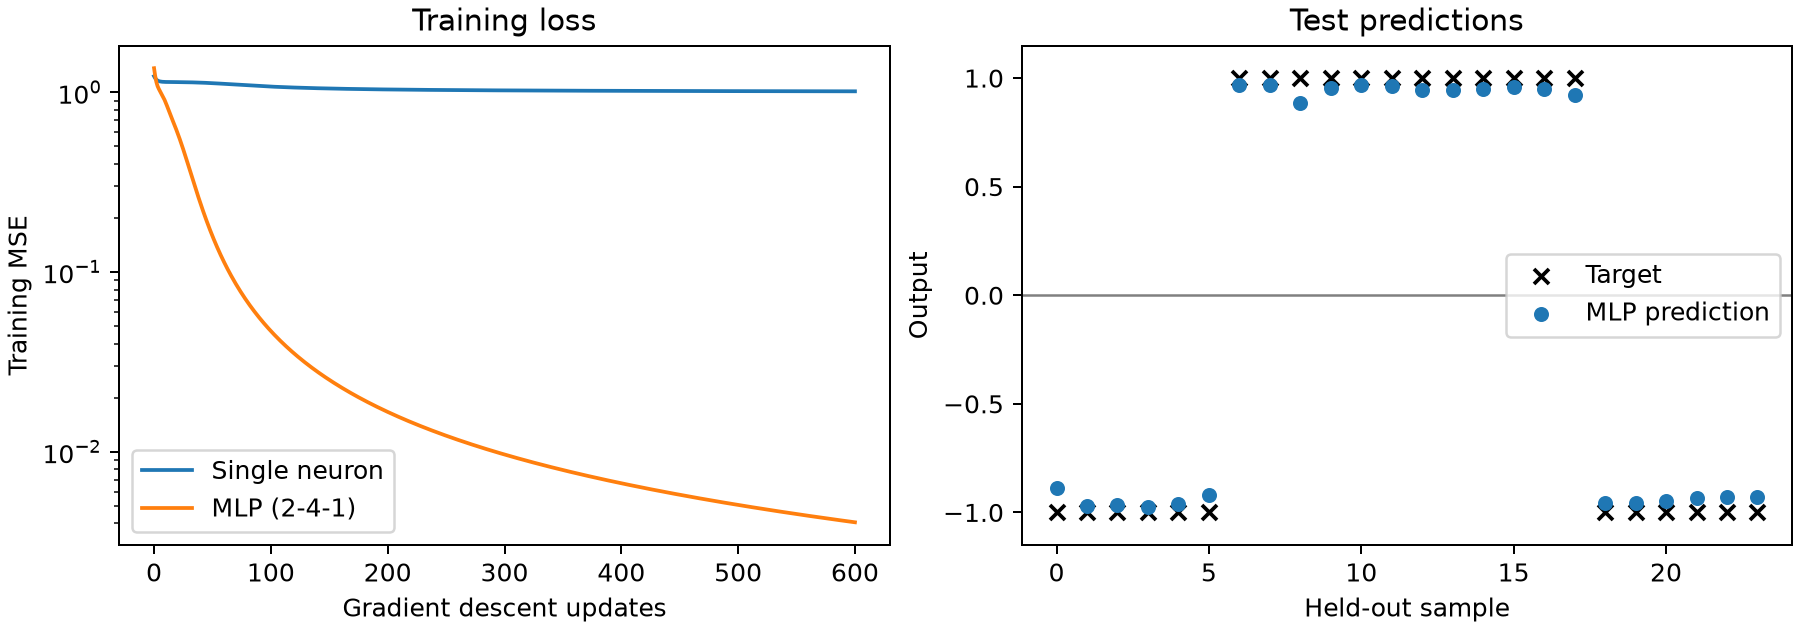

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].plot(baseline_history, label='Single neuron')
axes[0].plot(mlp_history, label='MLP (2-4-1)')
axes[0].set(xlabel='Gradient descent updates', ylabel='Training MSE',
            title='Training loss', yscale='log')
axes[0].legend()
predictions = [model(x).data for x in test_x]
axes[1].axhline(0, color='grey', lw=1)
axes[1].scatter(range(len(test_y)), test_y, label='Target', marker='x', color='black')
axes[1].scatter(range(len(test_y)), predictions, label='MLP prediction', s=25)
axes[1].set(xlabel='Held-out sample', ylabel='Output', title='Test predictions',
            ylim=(-1.15, 1.15))
axes[1].legend(loc='center right')
fig.savefig(FIGURES / 'training_results.png', dpi=180)
display(Image(filename=str(FIGURES / 'training_results.png')))
plt.close(fig)

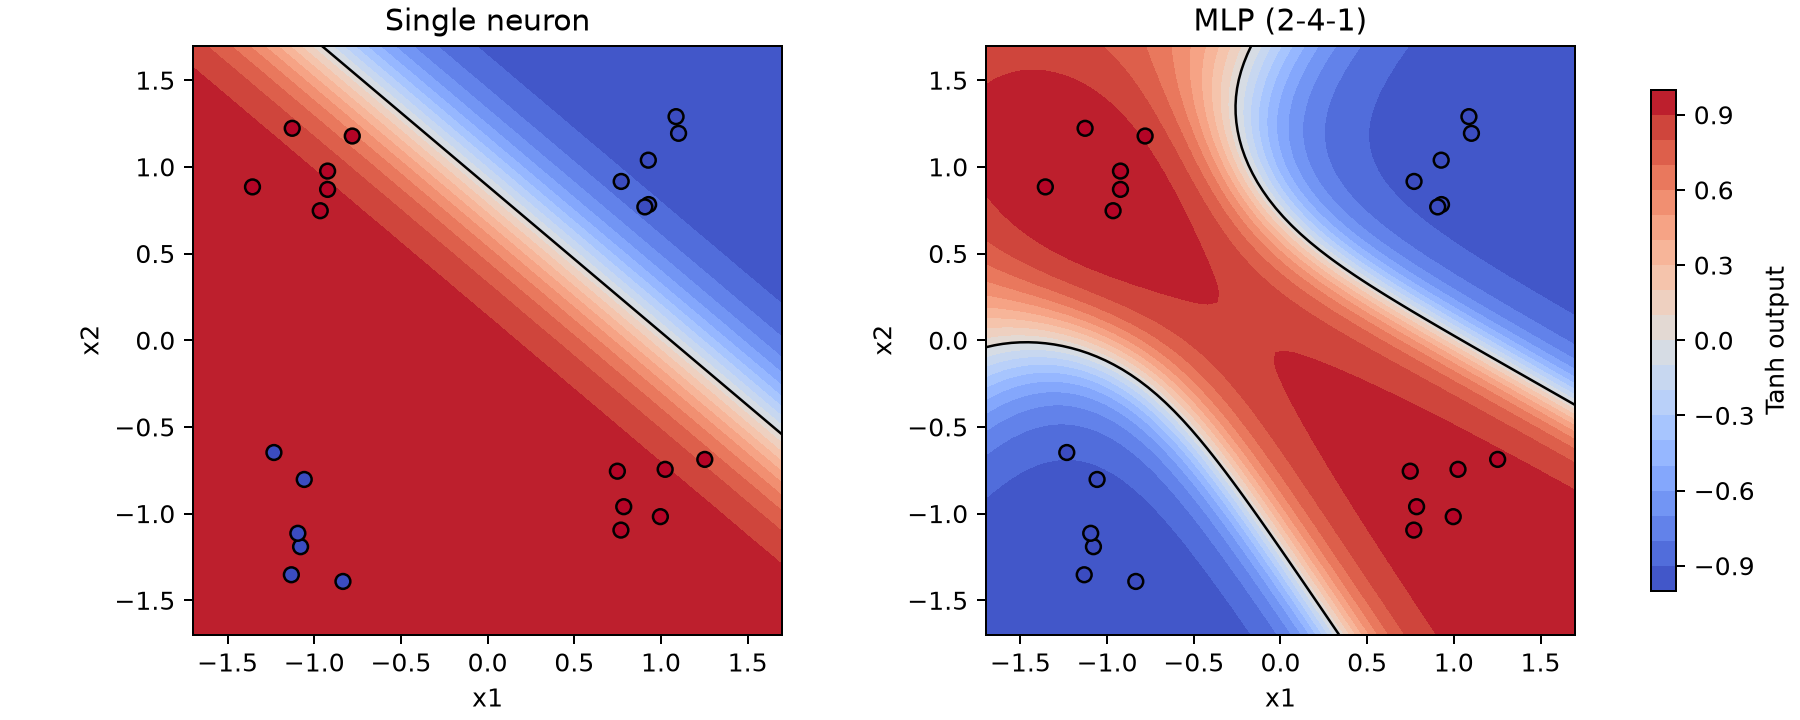

In [7]:
axis = np.linspace(-1.7, 1.7, 70)
xx, yy = np.meshgrid(axis, axis)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
test_points = np.array(test_x)
for ax, net, title in zip(axes, [baseline, model], ['Single neuron', 'MLP (2-4-1)']):
    zz = np.array([net([float(a), float(b)]).data
                   for a, b in zip(xx.ravel(), yy.ravel())]).reshape(xx.shape)
    surface = ax.contourf(xx, yy, zz, levels=np.linspace(-1, 1, 21),
                          cmap='coolwarm', vmin=-1, vmax=1)
    if zz.min() < 0 < zz.max():
        ax.contour(xx, yy, zz, levels=[0], colors='black', linewidths=1)
    ax.scatter(test_points[:, 0], test_points[:, 1], c=test_y, cmap='coolwarm',
               vmin=-1, vmax=1, edgecolors='black', s=35)
    ax.set(xlabel='x1', ylabel='x2', title=title, aspect='equal')
fig.colorbar(surface, ax=list(axes), label='Tanh output', shrink=0.85)
fig.savefig(FIGURES / 'decision_boundary.png', dpi=180)
display(Image(filename=str(FIGURES / 'decision_boundary.png')))
plt.close(fig)

In [8]:
exact_x = [[-1.0, -1.0], [-1.0, 1.0], [1.0, -1.0], [1.0, 1.0]]
exact_y = [-1.0, 1.0, 1.0, -1.0]
exact_predictions = [model(x).data for x in exact_x]
print('x1     x2     target   prediction')
for x, y, p in zip(exact_x, exact_y, exact_predictions):
    print(f'{x[0]:4.0f}   {x[1]:4.0f}     {y:4.0f}     {p:9.5f}')
assert all((1.0 if p >= 0 else -1.0) == y
           for p, y in zip(exact_predictions, exact_y))

results = {'seed': 7, 'data_seed': 23, 'epochs': EPOCHS,
           'learning_rate': LEARNING_RATE,
           'train_samples': len(train_x), 'test_samples': len(test_x),
           'max_gradient_error': max_gradient_error, 'models': summary,
           'exact_xor_predictions': exact_predictions}
(RESULTS / 'metrics.json').write_text(json.dumps(results, indent=2) + '\n')
(RESULTS / 'loss_history.json').write_text(json.dumps({
    'single_neuron': baseline_history, 'mlp': mlp_history}, indent=2) + '\n')
(RESULTS / 'mlp_parameters.json').write_text(json.dumps(
    [p.data for p in model.parameters()], indent=2) + '\n')
print('Saved metrics, loss histories, parameters and figures.')

x1     x2     target   prediction
  -1     -1       -1      -0.94974
  -1      1        1       0.96804
   1     -1        1       0.95820
   1      1       -1      -0.95212
Saved metrics, loss histories, parameters and figures.


## 5. Discussion

The MLP can learn the alternating XOR labels because the hidden neurons create
nonlinear features. One tanh neuron still has a straight zero-output boundary,
so it cannot represent all four XOR regions. Its loss gives a useful baseline.
The plots and saved metrics show the outcome for this fixed run.

This is a small synthetic example, not evidence of performance on real data.
There are only 24 held-out samples and one initialization seed. Scalar graphs
also create many Python objects and are slow compared with tensor operations.
The recursive DFS can hit Python's recursion limit on very deep graphs.
Gradients accumulate, so repeated backward calls on the same graph require
clearing intermediate gradients too; this demo instead rebuilds the graph.